
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [1]:

from pathlib import Path
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)



## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [2]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation-" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.
import pandas as pd

URLS = {"train": "train.csv","valid": "valid.csv", "test": "test.csv"}
SPLIT_SIZES = {}
NAMES = ["text", "target"]
df_train = pd.read_csv("train.csv", names=NAMES, header=1)
df_valid = pd.read_csv("valid.csv", names=NAMES, header=1)
df_test = pd.read_csv("test.csv", names=NAMES, header=1)
splits = {"train": df_train, "valid": df_valid, "test": df_test }
LABEL_MAP = {"__label__meta_plus_m": "plus", "__label__meta_minus_m": "minus", "__label__meta_zero": "zero", "__label__meta_amb": "amb"}
CLASSES = list(LABEL_MAP.values())

SPLIT_SIZES={"train": df_train.shape[0], "valid": df_valid.shape[0], "test": df_test.shape[0]}

for name, split in splits.items():
    SPLIT_SIZES[name] = split.shape[0]
    split["split"] = name
    split["target"] = split["target"].map(LABEL_MAP)

df_train.head()

,text,target,split
0,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train
1,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train
2,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train
3,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train
4,"Jest nie prawda co napisal ten internauta . Ten lekarz jest bardzo dobrym , przesympatycznym , milym i kulturalnym czlowiekiem . Nie jest tez prawda ze ogla...",plus,train


In [3]:
df_train.shape[1]

3


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [4]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))
SHOW_WORD_THRESHOLD = 20
audit_rows = []

# MIEJSCE NA KOD
for name, split in splits.items():
    audit_rows.append({
        "split": name,
        "rows": split.shape[0],
        "columns": split.shape[1],
        "missing_text": split.isna().sum(),
        "missing_target": split["target"].isna().sum(),
        "unique_labels": split["target"].value_counts(),
        "short_texts_counter": split.loc[split["text"].str.len() < SHOW_WORD_THRESHOLD].shape[0]
    })

pd.DataFrame(audit_rows)

,split,rows,columns,missing_text,missing_target,unique_labels,short_texts_counter
0,train,5782,3,text 0 target 0 split 0 dtype: int64,0,"target minus 2194 plus 1567 amb 1050 zero 971 Name: count, dtype: int64",1
1,valid,722,3,text 0 target 0 split 0 dtype: int64,0,"target minus 270 plus 209 zero 127 amb 116 Name: count, dtype: int64",0
2,test,721,3,text 0 target 0 split 0 dtype: int64,0,"target minus 299 plus 197 zero 117 amb 108 Name: count, dtype: int64",0



## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> Przykład formy: „Spodziewam się, że __minus__ będzie klasą dominującą, ponieważ __z moich własnych obserwacji wynika, że osoby sfrustrowane cześciej piszą opinie__.”


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [5]:
# TODO: tabela rozkładu klas dla każdego splitu

class_distribution = []
for name, split in splits.items():
    for target_class in CLASSES:
        class_distribution.append({
            "df_name": name,
            "target_class": target_class,
            "size": (split.loc[split["target"] == target_class].shape[0])
        })

# MIEJSCE NA KOD
pd_class_distribution = pd.DataFrame(class_distribution)
pd_class_distribution

,df_name,target_class,size
0,train,plus,1567
1,train,minus,2194
2,train,zero,971
3,train,amb,1050
4,valid,plus,209
5,valid,minus,270
6,valid,zero,127
7,valid,amb,116
8,test,plus,197
9,test,minus,299


In [6]:
pd_class_distribution["size"]

0     1567
1     2194
2      971
3     1050
4      209
5      270
6      127
7      116
8      197
9      299
10     117
11     108
Name: size, dtype: int64

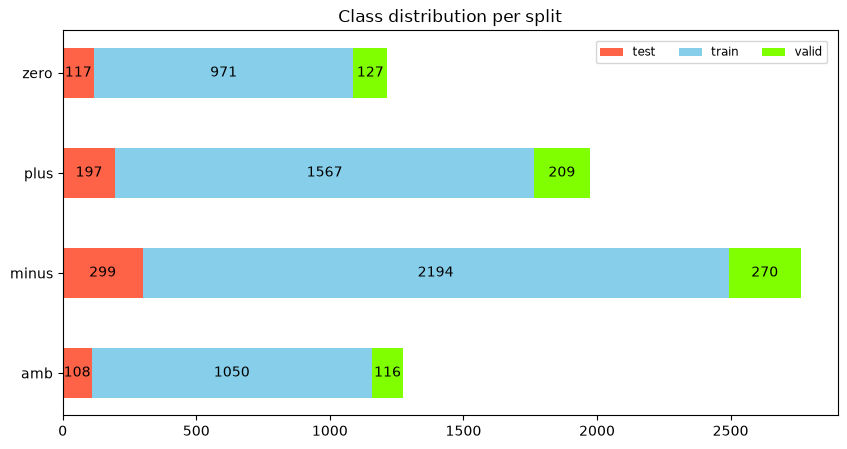

In [7]:
# TODO: wykres rozkładu klas
pivot_df = pd_class_distribution.pivot(index="target_class", columns="df_name", values="size").fillna(0)

data = pivot_df.values.astype(float)
data_cum = data.cumsum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

for i, (colname, color) in enumerate(zip(pivot_df.columns, ['tomato', 'skyblue', 'chartreuse'])):
    widths = data[:, i]
    starts = data_cum[:, i] - widths
    rects = ax.barh(pivot_df.index, widths, left=starts, height=0.5, label=colname, color=color)

    ax.bar_label(rects, label_type='center')

ax.legend(ncols=len(pivot_df.columns), bbox_to_anchor=(0.68, 0.9), loc='lower left', fontsize='small')
plt.title("Class distribution per split")
plt.show()


# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Dp wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [8]:
all_df = pd.concat(splits.values(), ignore_index=True)

# TODO: do dodania n_chars, n_words, n_words_split, n_lines.
feature_numbers = {'n_chars': []}
feature_numbers['n_chars'] = all_df['text'].apply(len)
feature_numbers['n_words'] = all_df['text'].str.findall(r"\w+").str.len()
feature_numbers['n_words_split'] = all_df['text'].str.split().str.len()
feature_numbers['n_lines'] = all_df['text'].str.split('\n').str.len()

feature_distribution = []

for key in feature_numbers.keys():
    feature_distribution.append({
        'name': key,
        'min': np.min(feature_numbers[key]),
        'average': np.average(feature_numbers[key]),
        'p_90': np.percentile(feature_numbers[key], 90),
        'p_95': np.percentile(feature_numbers[key], 95),
        'p_99': np.percentile(feature_numbers[key], 99),
        'max': np.max(feature_numbers[key]),
    })

In [9]:
# TODO: tabela statystyk długości
pd_feautre_distribution = pd.DataFrame(feature_distribution)
pd_feautre_distribution

,name,min,average,p_90,p_95,p_99,max
0,n_chars,1,777.128720,1294.0,1605.8,2335.28,5391
1,n_words,1,114.336471,191.0,242.0,352.76,774
2,n_words_split,1,136.337301,228.0,288.8,414.76,987
3,n_lines,1,1.000000,1.0,1.0,1.00,1


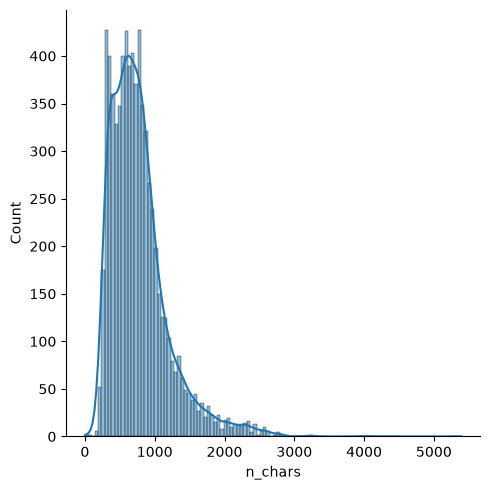

In [10]:
# TODO: histogram długości tekstów
import seaborn as sns
feature_numbers_df = pd.DataFrame(feature_numbers)

sns.displot(data=feature_numbers_df, x="n_chars", kde=True)

In [11]:
# TODO: skrajne obserwacje

# MIEJSCE NA KOD
sorted_all = all_df['text'].sort_values(key=lambda x: x.str.len())
longest_5 = sorted_all[-5:]
shortest_5 = sorted_all[:5]

print(longest_5)
print("------------------------------------")
print(shortest_5)

6348    Ten Hotel to jest kpina z klienta . Hotel jedynie ładnie wygląda na zdjęciach i z daleka . Zdjęcia były robione dawno temu jak powstał ten hotel i nie aktua...
5530    W hotelu gościmy regularnie od pięciu lat , magiczne miejsce nad klimatycznym jeziorem z dobra kuchnia oparta o lokalne produkty z masą ryb . Spory aquapark...
4491    Właśnie wrócili śmy z " weekendowego " pobytu w Amaxie , skusili śmy sie akurat na ten hotel po przeczytaniu pozytywnych opinii . Wolna była willa 4 osobowa...
4869    Wykupiła m w państwa Hotelu pobyt świąteczny od dnia 23 . 12 - 26 . 12 . 2016r . dla 3 osób dorosłych i dwóch kotków . Rezerwacji dokonała m w miesiącu paźd...
3199    Wybór sylwestrowego pakietu w tym hotelu za gigantyczne pieniądze ( jak na zaproponowane warunki i " atrakcje " ) to jeden z naszych największych błędów . K...
Name: text, dtype: str
------------------------------------
4475                                                                                 P
7038         


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [12]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

url_regex = r'https?://\S+|www\.\S+'
email_regex = r'\S+@\S+\.\S+'
punct_burst_regex = r'[!?]\s*[!?]'
uppercase_regex = r'[A-ZĄĆĘŁŃÓŚŹŻ]'

has_url = all_df['text'].str.contains(url_regex, na=False)
has_email = all_df['text'].str.contains(email_regex, na=False)
has_punct_burst = all_df['text'].str.contains(punct_burst_regex, na=False)
has_newline = all_df['text'].str.contains('\n')
is_very_short = (all_df['text'].str.len() < 20)
uppercase_letters = (all_df['text'].str.findall(uppercase_regex).str.len() / all_df['text'].str.len() > 0.5)

print(f'Has url sum: {has_url.sum()}')
print(f'Has email sum: {has_email.sum()}')
print(f'Has punct burtst sum: {has_punct_burst.sum()}')
print(f'Is veruy short rows: {is_very_short.sum()}')
print(f'Has new line sum: {has_newline.sum()}')
print(f'Uppercase letters rows: {uppercase_letters.sum()}')

Has url sum: 9
Has email sum: 0
Has punct burtst sum: 808
Is veruy short rows: 1
Has new line sum: 0
Uppercase letters rows: 10



# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [13]:
import unicodedata
# TODO:
# preprocessing

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

# MIEJSCE NA KOD

text_raw_test = df_test['text']
test_split_raw_duplicates = text_raw_test.duplicated().sum()

text_norm_test = text_raw_test.apply(lambda x: unicodedata.normalize('NFKC', x).lower().replace(" ", "").strip())
test_split_norm_duplicates = text_norm_test.duplicated().sum()

text_raw_train = df_train['text']
train_split_raw_duplicates = text_raw_train.duplicated().sum()

text_norm_train = text_raw_train.apply(lambda x: unicodedata.normalize('NFKC', x).lower().replace(" ", "").strip())
train_split_norm_duplicates = text_norm_train.duplicated().sum()

test_train_raw_duplicated = set(text_raw_test).intersection(set(text_raw_train))
test_train_norm_duplicated = set(text_norm_test).intersection(set(text_norm_train))

print(test_split_raw_duplicates)
print(test_split_norm_duplicates)
print("-------")
print(train_split_raw_duplicates)
print(train_split_norm_duplicates)
print("-------")
print(test_train_raw_duplicated)
print(test_train_norm_duplicated)


all_df['text_norm'] = all_df["text"].apply(lambda x: unicodedata.normalize('NFKC', x).lower().replace(" ", "").strip())


0
0
-------
0
0
-------
set()
set()



## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [14]:
import pandas as pd

# 20 przykładowych rekordów
data = {
    "text_norm": [
        # --- Przypadek 1: Leakage między train a test ---
        "świetny produkt polecam",      # train
        "świetny produkt polecam",      # test (LEAKAGE)
        
        # --- Przypadek 2: Leakage między train, val i test ---
        "nie polecam odradzam",         # train
        "nie polecam odradzam",         # val  (LEAKAGE)
        "nie polecam odradzam",         # test (LEAKAGE)
        
        # --- Przypadek 3: Duplikat, ale w tym samym splicie (NIE leakage!) ---
        "bateria trzyma krótko",        # train
        "bateria trzyma krótko",        # train (nunique == 1, więc funkcja to zignoruje)
        
        # --- Przypadek 4: Kolejny leakage (val i test) + sprzeczne etykiety ---
        "szybka dostawa",               # val
        "szybka dostawa",               # test (LEAKAGE)
        
        # --- Przypadek 5: Teksty unikalne (brak leakage) ---
        "ekran dotykowy działa płynnie", # train
        "jakość wykonania przeciętna",  # val
        "obsługa klienta na medal",     # test
        "aparat robi ładne zdjęcia",    # train
        "brak ładowarki w pudełku",     # train
        "głośniki grają bardzo cicho",  # val
        "laptop przegrzewa się w grach",# test
        "klawiatura jest wygodna",      # train
        
        # --- Przypadek 6: Jeszcze jeden leakage z wielokrotnym trainem ---
        "totalna porażka nie kupujcie", # train
        "totalna porażka nie kupujcie", # train
        "totalna porażka nie kupujcie", # test (LEAKAGE)

        "dupa"
    ],
    "split": [
        "train", "test",
        "train", "val", "test",
        "train", "train",
        "val", "test",
        "train", "val", "test", "train", "train", "val", "test", "train",
        "train", "train", "test",
        "test"
    ],
    "label": [
        "positive", "positive",
        "negative", "negative", "negative",
        "negative", "negative",
        "positive", "negative",  # uwaga: sprzeczna etykieta przy tym samym tekście!
        "positive",
        "neutral",
        "positive",
        "positive",
        "negative",
        "negative",
        "negative",
        "positive",
        "negative", "negative", "negative",
        "positive"
    ]
}

test_df = pd.DataFrame(data)

In [15]:

def audit_split_leakage(df, text_col="text_norm", split_col="split", label_col = "label"):
    leakage_mask =  df.groupby(text_col)[split_col].transform('nunique') > 1

    return (
        df[leakage_mask].groupby(text_col)
        .agg(
            count = (split_col, 'count'),
            splits = (split_col, lambda x: sorted(x.unique().tolist())),
            lables = (label_col, lambda x: sorted(x.unique().tolist()))
        )
        .sort_values('count', ascending = False)
    )

print(audit_split_leakage(test_df))

                              count              splits                lables
text_norm                                                                    
nie polecam odradzam              3  [test, train, val]            [negative]
totalna porażka nie kupujcie      3       [test, train]            [negative]
szybka dostawa                    2         [test, val]  [negative, positive]
świetny produkt polecam           2       [test, train]            [positive]



# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [72]:
# TODO nearest_other_neighbour
N_NEIGHBORS = 2
SIMILARITY_THRESHOLD = 0.90

sample = all_df.sample(5000, random_state=RANDOM_STATE)
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))

X = vectorizer.fit_transform(sample['text_norm'])

def nearest_other_neighbor(X):
    knn = NearestNeighbors(metric="cosine")
    knn.fit(X)

    distances, indices = knn.kneighbors(X, n_neighbors=N_NEIGHBORS)
    j = indices[ :, 1]
    sim = 1 - distances[: , 1]
    return j, sim

    

# MIEJSCE NA KOD
j, sim = nearest_other_neighbor(X)

In [73]:
pairs = []

pairs = pd.DataFrame({
    "i": range(len(sample)),
    "j": j,
    "sim": sim
})

pairs = pairs[pairs["sim"] >=  SIMILARITY_THRESHOLD]
pairs = pairs[pairs["i"] < pairs["j"]]

pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]]
pairs["i_text"] = sample["text"].values[pairs["i"]]
pairs["j_text"] = sample["text"].values[pairs["j"]]
pairs

,i,j,sim,cross_split,i_text,j_text
105,105,2021,0.930430,False,"Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotel...","Wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do Wojskowej Agencji Mieszkaniowej . Gru..."
4658,4658,4881,0.990663,True,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H...","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H..."



# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [ ]:
# MIEJSCE NA KOD


# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?


In [ ]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["text"], train_part["target"])
    pred = probe.predict(test_part["text"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }

# Wynik bazowy na oficjalnym splicie:
clean_score = evaluate_probe(train_df, test_df)
clean_score


In [ ]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["text"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test_df.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train_df, leaked], ignore_index=True)
    probe.fit(train_leaky["text"], train_leaky["target"])
    m = test_df.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test_df)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test_df[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test_df[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)


## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?
2. Czy wynik wzrósł tak mocno, jak było oczekiwane?
3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?
4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?
5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?
6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [ ]:
# TODO: zdefiniować clean_df zgodnie z polityką czyszczenia
# clean_df = ...

import sys, sklearn

clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": [],   # np. {"op": "drop_cross_split_dups_from_train", "removed": n}
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))

# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 |  |  |  |
| 2 |  |  |  |
| 3 |  |  |  |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.



# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.

### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.

### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.


# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [ ] sanity check wszystkich splitów;
- [ ] rozkład klas;
- [ ] analizę długości;
- [ ] status zaszumienia;
- [ ] status duplikatów;
- [ ] `audit_split_leakage(...)`;
- [ ] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [ ] porównanie oficjalnego i losowego splitu;
- [ ] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [ ] `artifacts/polemo2_clean.parquet`;
- [ ] `artifacts/splits.json`;
- [ ] `dataset_card.md`;
- [ ] przykłady pomyłek;
- [ ] obserwacje końcowe.